In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch
import pyarrow
from pathlib import Path

In [3]:
BASE_DIR = Path.cwd().resolve().parent
DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"

In [4]:
ruta_mapa = BASE_DIR / "data"/"processed"/"LIM_DEPARTAMENTAL_PERU_MIN.json"
ruta_provinvial = BASE_DIR / "data"/"processed"/"LIM_PROVINCIAL_PERU.json"
peru = gpd.read_file(ruta_mapa)
provincias_peru = gpd.read_file(ruta_provinvial)

In [5]:
df_cap600 = pd.read_parquet(RAW_DIR / "14_CAP600.parquet")
df_caratula = pd.read_parquet(RAW_DIR / "CARATULA.parquet")

In [6]:
df_ancash = df_cap600.loc[df_cap600["NOMBREDD"] == "ANCASH"]
df_lalibertad = df_cap600.loc[df_cap600["NOMBREDD"] == "LA LIBERTAD"]

In [7]:
caratula_ancash = df_caratula.loc[df_caratula["NOMBREDD"] == "ANCASH"]
caratula_lalibertad = df_caratula.loc[df_caratula["NOMBREDD"] == "LA LIBERTAD"]

In [8]:
map_ancash = peru.loc[peru["NOMBDEP"] == "ANCASH"]
map_prov_ancash = provincias_peru.loc[provincias_peru["NOMBDEP"]== "ANCASH"]
map_lalibertad = peru.loc[peru["NOMBDEP"] == "LA LIBERTAD"]
map_prov_lalibertad = provincias_peru.loc[provincias_peru["NOMBDEP"]== "LA LIBERTAD"]

In [9]:
puntos_ancash = gpd.GeoDataFrame(
    caratula_ancash,
    geometry = gpd.points_from_xy(
        caratula_ancash["LONGITUD"],
        caratula_ancash["LATITUD"]
    ),
    crs = "EPSG:4326"
).copy()

In [10]:
puntos_lalibertad = gpd.GeoDataFrame(
    caratula_lalibertad,
    geometry = gpd.points_from_xy(
        caratula_lalibertad["LONGITUD"],
        caratula_lalibertad["LATITUD"]
    ),
    crs = "EPSG:4326"
).copy()

## La Libertad

### Manejo de residuos de cultivos

In [11]:
manejo_res_cult = {
    "P601_1": "Incineración",
    "P601_2": "Alimento animales",
    "P601_3": "Desecho",
    "P601_4": "Abono",
    "P601_5": "Deja en el campo",
    "P601_6": "Otro"
}

columnas_manejo_res_cult = list(manejo_res_cult.keys())

In [66]:
frec_manejo_res_cult = (
    df_lalibertad[columnas_manejo_res_cult]
    .sum()
    .sort_values(ascending=False)
    .rename(index=manejo_res_cult)
)

frer_manejo_res_cult = (frec_manejo_res_cult/frec_manejo_res_cult.sum()).round(2)
pctj_manejo_res_cult = frer_manejo_res_cult*100

In [67]:
tabla_manejo_res_cult = pd.DataFrame({"frec": frec_manejo_res_cult, "frer": frer_manejo_res_cult, "pctj": pctj_manejo_res_cult})
tabla_manejo_res_cult

,frec,frer,pctj
Deja en el campo,969.0,0.40,40.0
Alimento animales,548.0,0.23,23.0
Abono,543.0,0.22,22.0
Incineración,311.0,0.13,13.0
Desecho,48.0,0.02,2.0
Otro,2.0,0.00,0.0


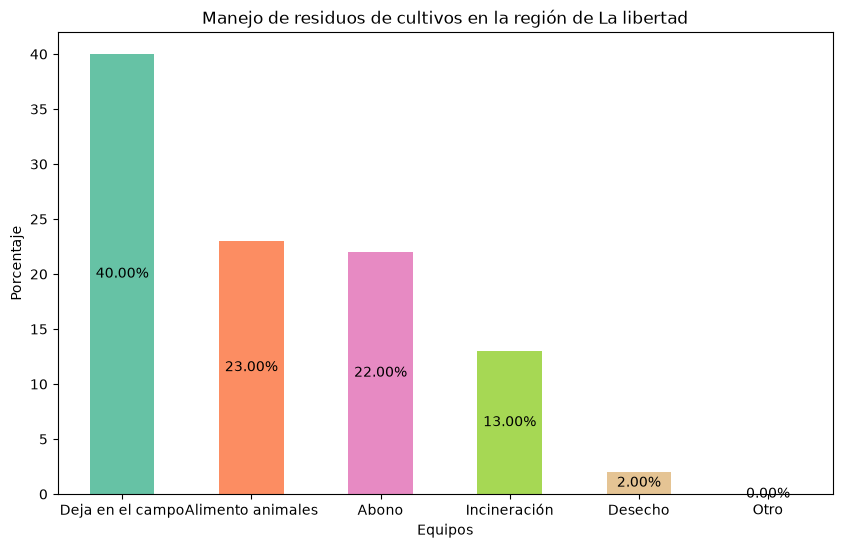

In [68]:
cmap = plt.get_cmap("Set2", len(tabla_manejo_res_cult))
colores = [cmap(i) for i in range(len(tabla_manejo_res_cult))]

gr_reg_manejo_res_cult = tabla_manejo_res_cult["pctj"].plot(
    kind = "bar",
    stacked = False,
    figsize = (10, 6),
    color = colores,
)
gr_reg_manejo_res_cult.set_title("Manejo de residuos de cultivos en la región de La libertad")
gr_reg_manejo_res_cult.set_xlabel("Equipos")
gr_reg_manejo_res_cult.set_ylabel("Porcentaje")  


for container in gr_reg_manejo_res_cult.containers:
    gr_reg_manejo_res_cult.bar_label(
        container,
        fmt = "%.2f%%",
        label_type = "center",
        fontsize = 10
    )
plt.xticks(rotation = 0)
plt.show()

### Manejo de residuos de animales

In [14]:
manejo_res_anim = {
    "P602_1": "Incinera",
    "P602_2": "Entierra",
    "P602_3": "Desecha",
    "P602_4": "Abono",
    "P602_5": "Combustible",
    "P602_6": "Deja en el campo",
    "P602_7": "Otro",
    "P602_8": "No aplica"
}

columnas_manejo_res_anim = list(manejo_res_anim.keys())

In [69]:
frec_manejo_res_anim = (
    df_lalibertad[columnas_manejo_res_anim]
    .sum()
    .sort_values(ascending=False)
    .rename(index = manejo_res_anim)
)

frer_manejo_res_anim = (frec_manejo_res_anim/frec_manejo_res_anim.sum()).round(2)
pctj_manejo_res_anim =  frer_manejo_res_anim*100

In [70]:
tabla_manejo_res_anim = pd.DataFrame({"frec":frec_manejo_res_anim, "frer":frer_manejo_res_anim, "pctj":pctj_manejo_res_anim})
tabla_manejo_res_anim

,frec,frer,pctj
Abono,723.0,0.50,50.0
Deja en el campo,604.0,0.42,42.0
Desecha,74.0,0.05,5.0
Incinera,31.0,0.02,2.0
Combustible,16.0,0.01,1.0
Entierra,7.0,0.00,0.0
Otro,0.0,0.00,0.0
No aplica,0.0,0.00,0.0


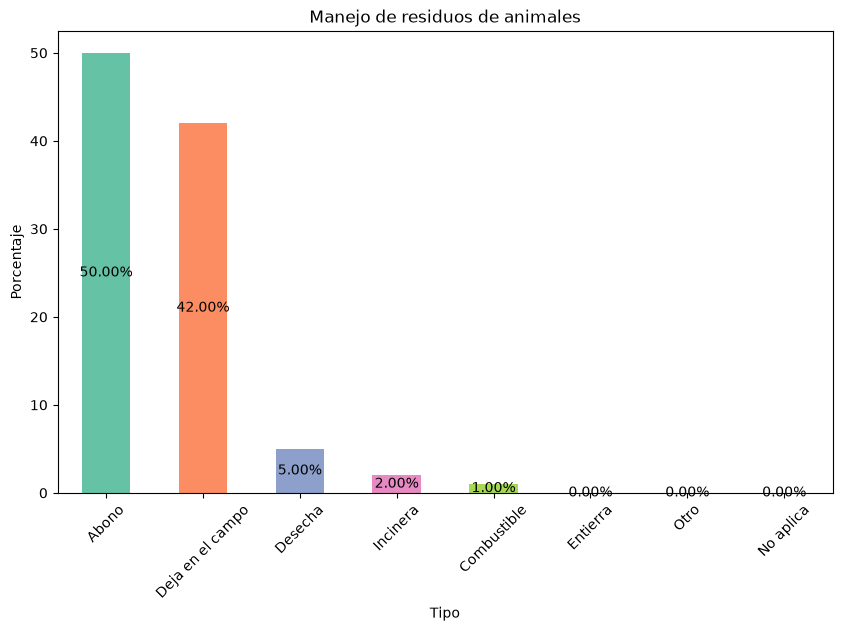

In [71]:
cmap = plt.get_cmap("Set2", len(tabla_manejo_res_anim))
colores = [cmap(i) for i in range(len(tabla_manejo_res_anim))]

plt.figure(figsize=(9,9))

gr_reg_manejo_res_anim = tabla_manejo_res_anim["pctj"].plot(
    kind = "bar",
    stacked = False,
    figsize = (10, 6),
    color = colores,
)
gr_reg_manejo_res_anim.set_title("Manejo de residuos de animales")
gr_reg_manejo_res_anim.set_xlabel("Tipo")
gr_reg_manejo_res_anim.set_ylabel("Porcentaje")  


for container in gr_reg_manejo_res_anim.containers:
    gr_reg_manejo_res_anim.bar_label(
        container,
        fmt = "%.2f%%",
        label_type = "center",
        fontsize = 10
    )
plt.xticks(rotation = 45)
plt.show()

### Actividad en unidades en el último año

In [17]:
df_lalibertad["P142_1"].value_counts()

P142_1
1.0    1367
0.0      48
Name: count, dtype: int64

In [18]:
df_lalibertad["P142_2"].value_counts()

P142_2
1    988
0    427
Name: count, dtype: int64

In [19]:
df_lalibertad["P142_3"].value_counts()

P142_3
0.0    1377
1.0      38
Name: count, dtype: int64

In [20]:
tabla_actividad = df_lalibertad[["P142_1", "P142_2", "P142_3", "NSEGM", "UA"]]

In [21]:
actividad_merge = pd.merge(
    puntos_lalibertad,
    tabla_actividad,
    on = ["NSEGM", "UA"],
    how = "outer"
)

In [22]:
condiciones_actividad = [
    ((actividad_merge["P142_1"] == 1) & (actividad_merge["P142_2"] == 0)).fillna(False),
    ((actividad_merge["P142_1"] == 0) & (actividad_merge["P142_2"] == 1)).fillna(False),
    ((actividad_merge["P142_1"] == 1) & (actividad_merge["P142_2"] == 1)).fillna(False),
    ((actividad_merge["P142_1"] == 0) & (actividad_merge["P142_2"] == 0)).fillna(False)
]

categorias_actividad = ["AGRÍCOLA", "PECUARIA", "AMBAS", "INACTIVA"]

actividad_merge["ACTIVIDAD"] = np.select(
    condiciones_actividad,
    categorias_actividad,
    default = pd.NA
)

In [23]:
condiciones_actividad_color = [
    (actividad_merge["ACTIVIDAD"] == "AGRÍCOLA").fillna(False),
    (actividad_merge["ACTIVIDAD"] == "PECUARIA").fillna(False),
    (actividad_merge["ACTIVIDAD"] == "AMBAS").fillna(False),
    (actividad_merge["ACTIVIDAD"] == "INACTIVA").fillna(False)
]

colores_actividad = ["deepskyblue", "tomato", "lightgreen", "black"]

actividad_merge["color"] = np.select(
    condiciones_actividad_color,
    colores_actividad,
    default = "silver"
)

In [57]:
actividad_merge = actividad_merge[["LATITUD", "LONGITUD", "geometry","P142_1", "P142_2", "P142_3", "ACTIVIDAD", "color"]]
actividad_merge

,LATITUD,LONGITUD,geometry,P142_1,P142_2,P142_3,ACTIVIDAD,color
0,-8.589419,-78.704158,POINT (-78.70416 -8.58942),1.0,1.0,0.0,AMBAS,lightgreen
1,-8.589419,-78.704158,POINT (-78.70416 -8.58942),1.0,1.0,0.0,AMBAS,lightgreen
2,-8.589419,-78.704158,POINT (-78.70416 -8.58942),1.0,0.0,0.0,AGRÍCOLA,deepskyblue
3,-8.465884,-78.391016,POINT (-78.39102 -8.46588),1.0,1.0,0.0,AMBAS,lightgreen
4,-8.696221,-78.383080,POINT (-78.38308 -8.69622),1.0,0.0,0.0,AGRÍCOLA,deepskyblue
...,...,...,...,...,...,...,...,...
1438,-7.812586,-79.324951,POINT (-79.32495 -7.81259),1.0,0.0,0.0,AGRÍCOLA,deepskyblue
1439,-7.812586,-79.324951,POINT (-79.32495 -7.81259),0.0,0.0,1.0,INACTIVA,black
1440,-7.812586,-79.324951,POINT (-79.32495 -7.81259),1.0,0.0,0.0,AGRÍCOLA,deepskyblue
1441,-7.836422,-78.819376,POINT (-78.81938 -7.83642),1.0,1.0,0.0,AMBAS,lightgreen


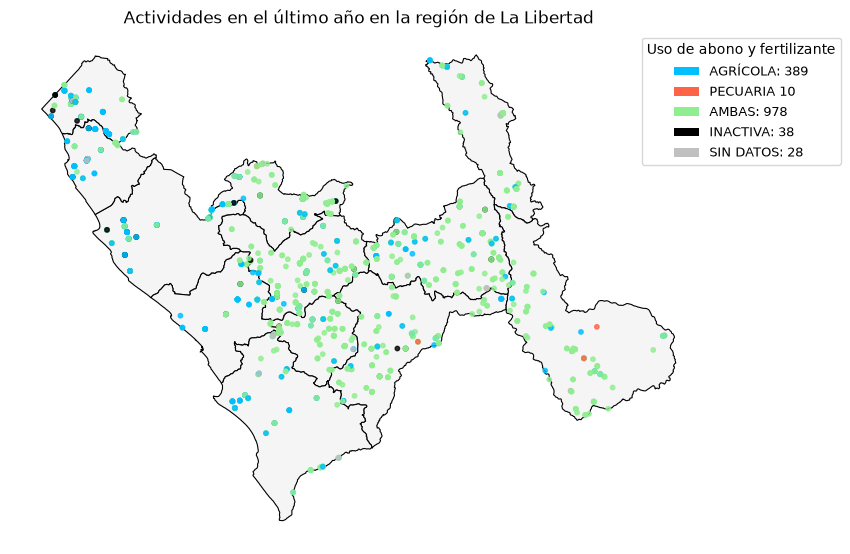

In [60]:
fig, ax = plt.subplots(figsize=(9, 9))

map_prov_lalibertad.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="black",
    linewidth=0.8
)

actividad_merge.plot(
    ax=ax,
    color=actividad_merge["color"],
    markersize=10,
    alpha=0.8
)

# Leyenda
leyenda = [
    Patch(facecolor="deepskyblue", label=f"AGRÍCOLA: {actividad_merge["color"].value_counts(dropna=False)["deepskyblue"]}"),
    Patch(facecolor="tomato", label=f"PECUARIA {actividad_merge["color"].value_counts(dropna=False)["tomato"]}"),
    Patch(facecolor="lightgreen", label=f"AMBAS: {actividad_merge["color"].value_counts(dropna=False)["lightgreen"]}"),
    Patch(facecolor="black", label=f"INACTIVA: {actividad_merge["color"].value_counts(dropna=False)["black"]}"),
    Patch(facecolor="silver", label=f"SIN DATOS: {actividad_merge["color"].value_counts(dropna=False)["silver"]}")
]

ax.legend(
    handles=leyenda,
    title="Uso de abono y fertilizante",
    loc="upper right",
    fontsize=9,
    title_fontsize=10,
    bbox_to_anchor = (1.2,1)
)

ax.set_title("Actividades en el último año en la región de La Libertad")
ax.set_axis_off()

plt.show()

### Lugar de almacenamiento de la producción

In [26]:
almacen = {
    "P606_1": "Lugar refrigerado",
    "P606_2": "Intemperie",
    "P606_3": "Cuarto ventilado",
    "P606_4": "Cuarto inadecuado",
    "P606_6": "Venta inmediata",
    "P606_7": "No para consumo humano",
    "P606_5": "Otro"
}

columnas_almacen = list(almacen.keys())

In [79]:
frec_almacen = (
    df_lalibertad[columnas_almacen]
    .sum()
    .sort_values(ascending = False)
    .rename(index = almacen)
)

frer_almacen = (frec_almacen/frec_almacen.sum()).round(2)
pctj_almacen = frer_almacen*100

In [80]:
tabla_almacen = pd.DataFrame({"frec": frec_almacen, "frer": frer_almacen, "pctj": pctj_almacen})
tabla_almacen

,frec,frer,pctj
Cuarto ventilado,933.0,0.41,41.0
Venta inmediata,853.0,0.37,37.0
Cuarto inadecuado,336.0,0.15,15.0
Lugar refrigerado,86.0,0.04,4.0
Intemperie,36.0,0.02,2.0
No para consumo humano,32.0,0.01,1.0
Otro,3.0,0.00,0.0


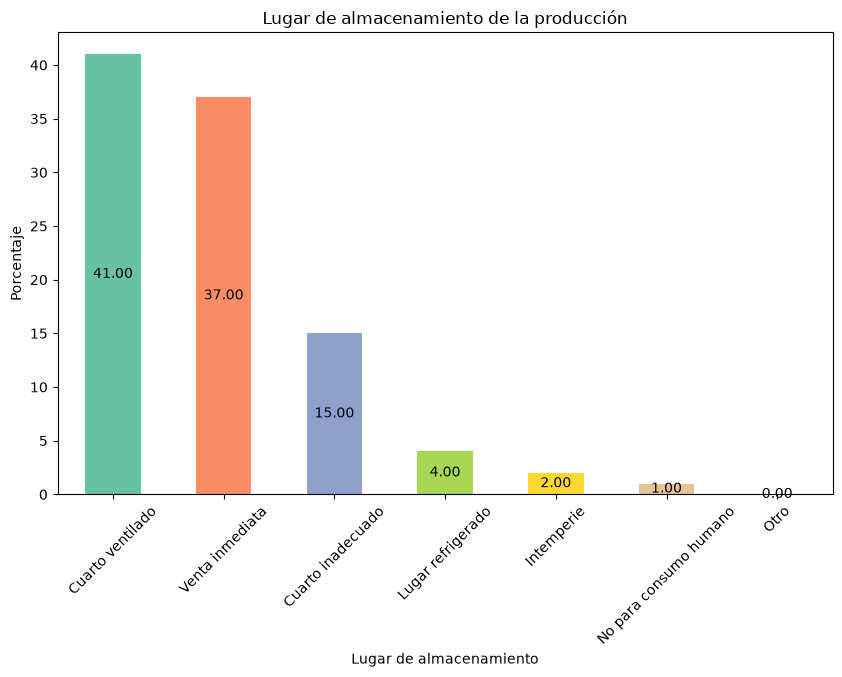

In [81]:
cmap = plt.get_cmap("Set2", len(tabla_almacen))
colores = [cmap(i) for i in range(len(tabla_almacen))]

gr_reg_almacen = tabla_almacen["pctj"].plot(
    kind = "bar",
    stacked = False,
    figsize = (10, 6),
    color = colores,
)
gr_reg_almacen.set_title("Lugar de almacenamiento de la producción")
gr_reg_almacen.set_xlabel("Lugar de almacenamiento")
gr_reg_almacen.set_ylabel("Porcentaje")  


for container in gr_reg_almacen.containers:
    gr_reg_almacen.bar_label(
        container,
        fmt = "%.2f",
        label_type = "center",
        fontsize = 10
    )
plt.xticks(rotation = 45)
plt.show()